In [5]:
import pandas as pd 

import matplotlib.pyplot as plt 

import seaborn as sns 

from sklearn.linear_model import LogisticRegression 

from sklearn.model_selection import train_test_split

In [6]:
df=pd.read_csv(r"C:\Users\Srushti Patil\OneDrive\Desktop\Introtallent\Proj_data\Investment Prediction\Investment Prediction\Investment.csv")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,Invested
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,No
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,No
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,Yes
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,No
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,Yes


In [7]:
df.shape

(41188, 21)

In [8]:
df["Invested"]=df["Invested"].replace(["Yes","No"],[1,0])

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\1419122122.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Invested"]=df["Invested"].replace(["Yes","No"],[1,0])


In [9]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,Invested
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


In [10]:
df.dtypes

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp_var_rate      float64
cons_price_idx    float64
cons_conf_idx     float64
euribor3m         float64
nr_employed       float64
Invested            int64
dtype: object

##### if missing values are there either--
 * impute it--replace using *mean()--no skewness in data 
                            *median()-- skewness in data 
                            *mode()-- for categorical data 
* delete or remove it 

In [11]:
df.isnull().sum() 

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp_var_rate      0
cons_price_idx    0
cons_conf_idx     0
euribor3m         0
nr_employed       0
Invested          0
dtype: int64

##### check outliers for numerical data 

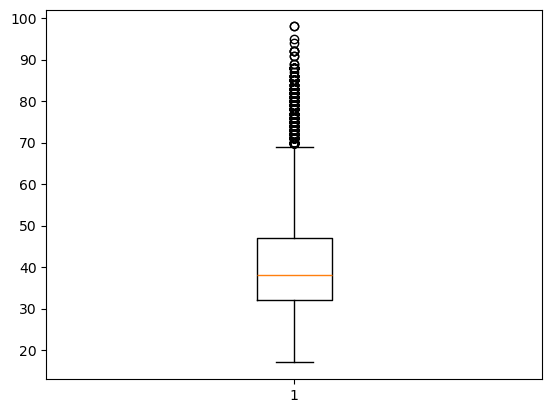

In [12]:
plt.boxplot(df["age"])
plt.show()

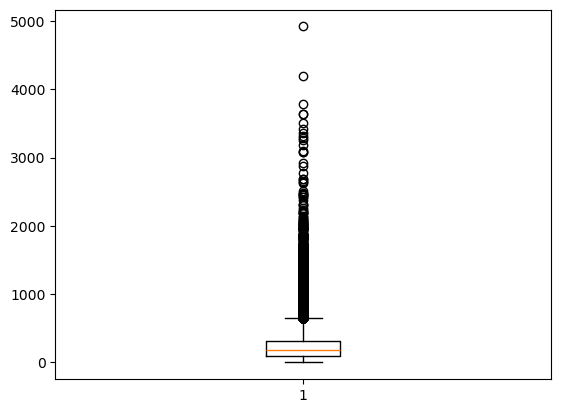

In [13]:
plt.boxplot(df["duration"])
plt.show()

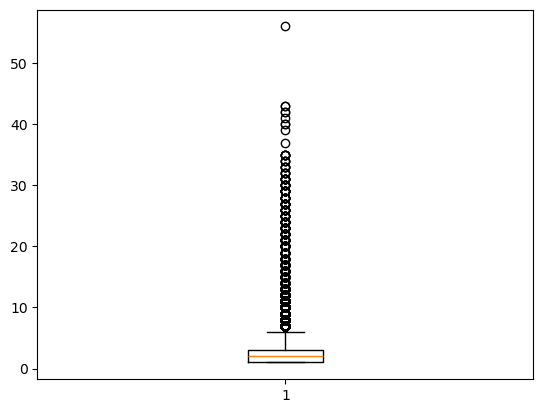

In [14]:
plt.boxplot(df["campaign"])
plt.show()

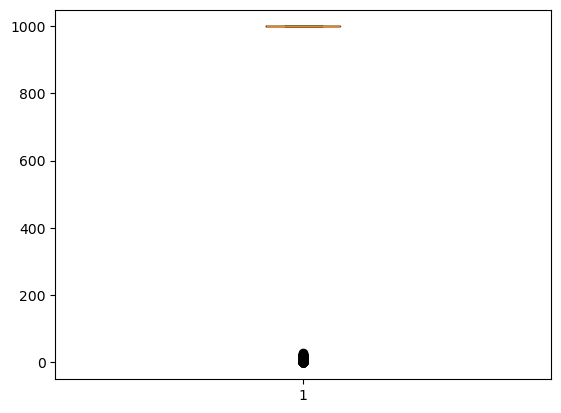

In [15]:
plt.boxplot(df["pdays"])
plt.show()

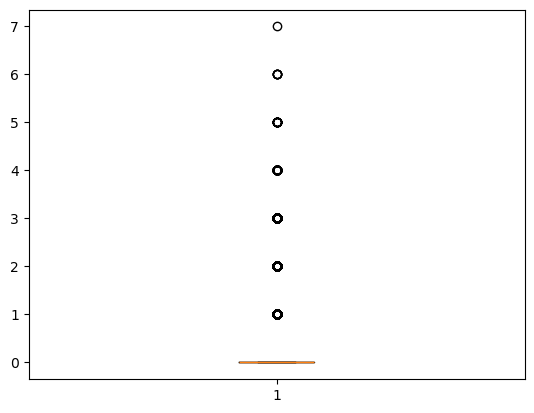

In [16]:
plt.boxplot(df["previous"])
plt.show()

In [17]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

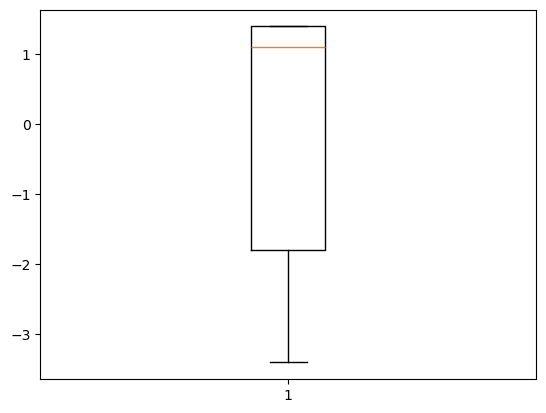

In [18]:
plt.boxplot(df["emp_var_rate"])
plt.show()

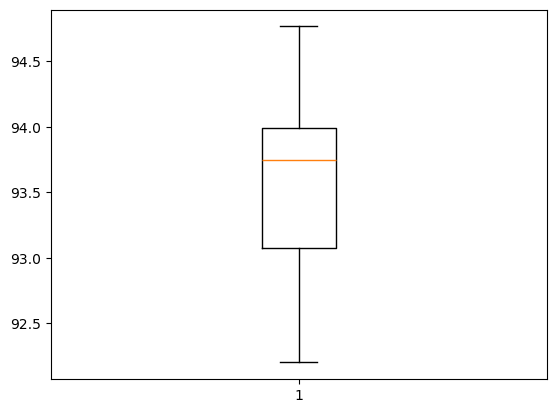

In [19]:
plt.boxplot(df["cons_price_idx"])
plt.show()

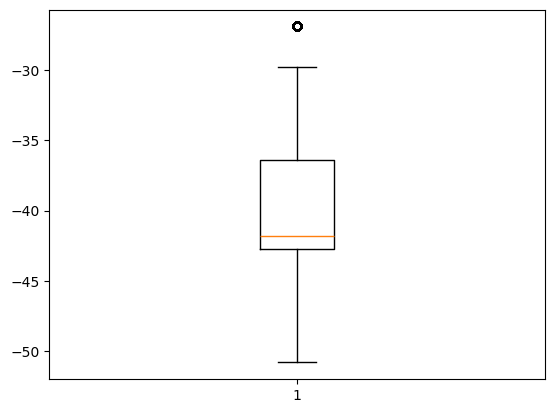

In [20]:
plt.boxplot(df["cons_conf_idx"])
plt.show()

In [21]:
def remove_outliers(d,c):
    q1=d[c].quantile(0.25)
    q3=d[c].quantile(0.75)
    iqr=q3-q1

    ub=q3+1.5*iqr
    lb=q1-1.5*iqr
    
    data_clean= d[(d[c]>lb) & (d[c]<ub)]
    return data_clean 

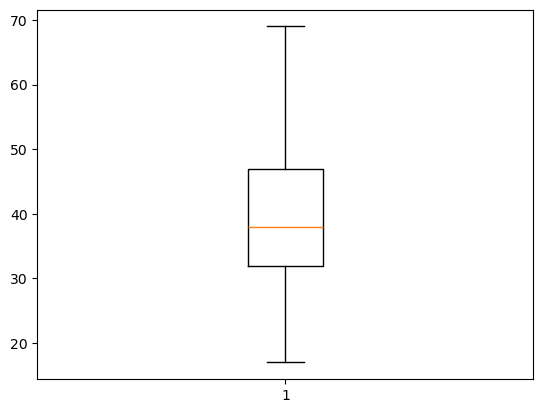

In [22]:
df=remove_outliers(df,"age")
plt.boxplot(df["age"])
plt.show()

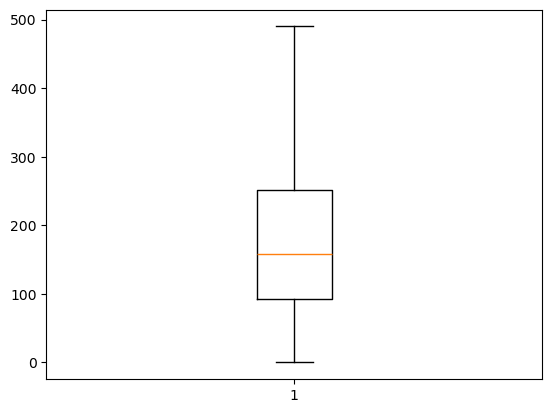

In [28]:
df=remove_outliers(df,"duration")
plt.boxplot(df["duration"])
plt.show()

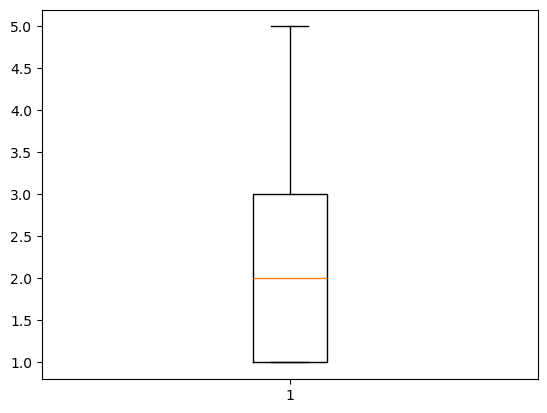

In [29]:
df=remove_outliers(df,"campaign")
plt.boxplot(df["campaign"])
plt.show()

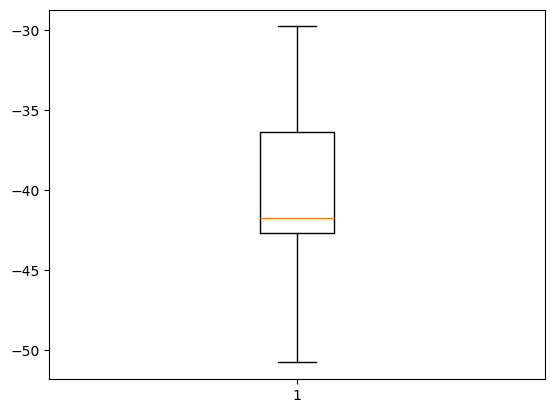

In [30]:
df=remove_outliers(df,"cons_conf_idx")
plt.boxplot(df["cons_conf_idx"])
plt.show()

In [31]:
df["job"].unique()

array(['blue-collar', 'technician', 'management', 'services', 'retired',
       'admin.', 'housemaid', 'unemployed', 'entrepreneur',
       'self-employed', 'unknown', 'student'], dtype=object)

In [32]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

In [33]:
df["marital"].unique()

array(['married', 'single', 'divorced', 'unknown'], dtype=object)

In [34]:
df["education"].unique()

array(['basic.4y', 'unknown', 'university.degree', 'high.school',
       'basic.9y', 'professional.course', 'basic.6y', 'illiterate'],
      dtype=object)

In [35]:
df["education"]=df["education"].replace(["basic.4y","basic.6y","basic.9y"],["basic","basic","basic"])
df["education"].unique()

array(['basic', 'unknown', 'university.degree', 'high.school',
       'professional.course', 'illiterate'], dtype=object)

In [36]:
df["default"].unique()

array(['unknown', 'no', 'yes'], dtype=object)

In [37]:
df["housing"].unique()

array(['yes', 'no', 'unknown'], dtype=object)

In [38]:
df["loan"].unique()

array(['no', 'yes', 'unknown'], dtype=object)

In [39]:
df["contact"].unique()

array(['cellular', 'telephone'], dtype=object)

In [40]:
df["month"].unique()

array(['aug', 'nov', 'jun', 'apr', 'may', 'jul', 'mar', 'sep', 'oct',
       'dec'], dtype=object)

In [41]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

In [42]:
df["day_of_week"].unique()

array(['thu', 'fri', 'mon', 'tue', 'wed'], dtype=object)

In [43]:
df["previous"].unique()

array([0, 2, 1, 3, 4, 5, 7, 6])

In [44]:
df["poutcome"].unique()

array(['nonexistent', 'success', 'failure'], dtype=object)

#### uses distribution using pairplot and distplot 

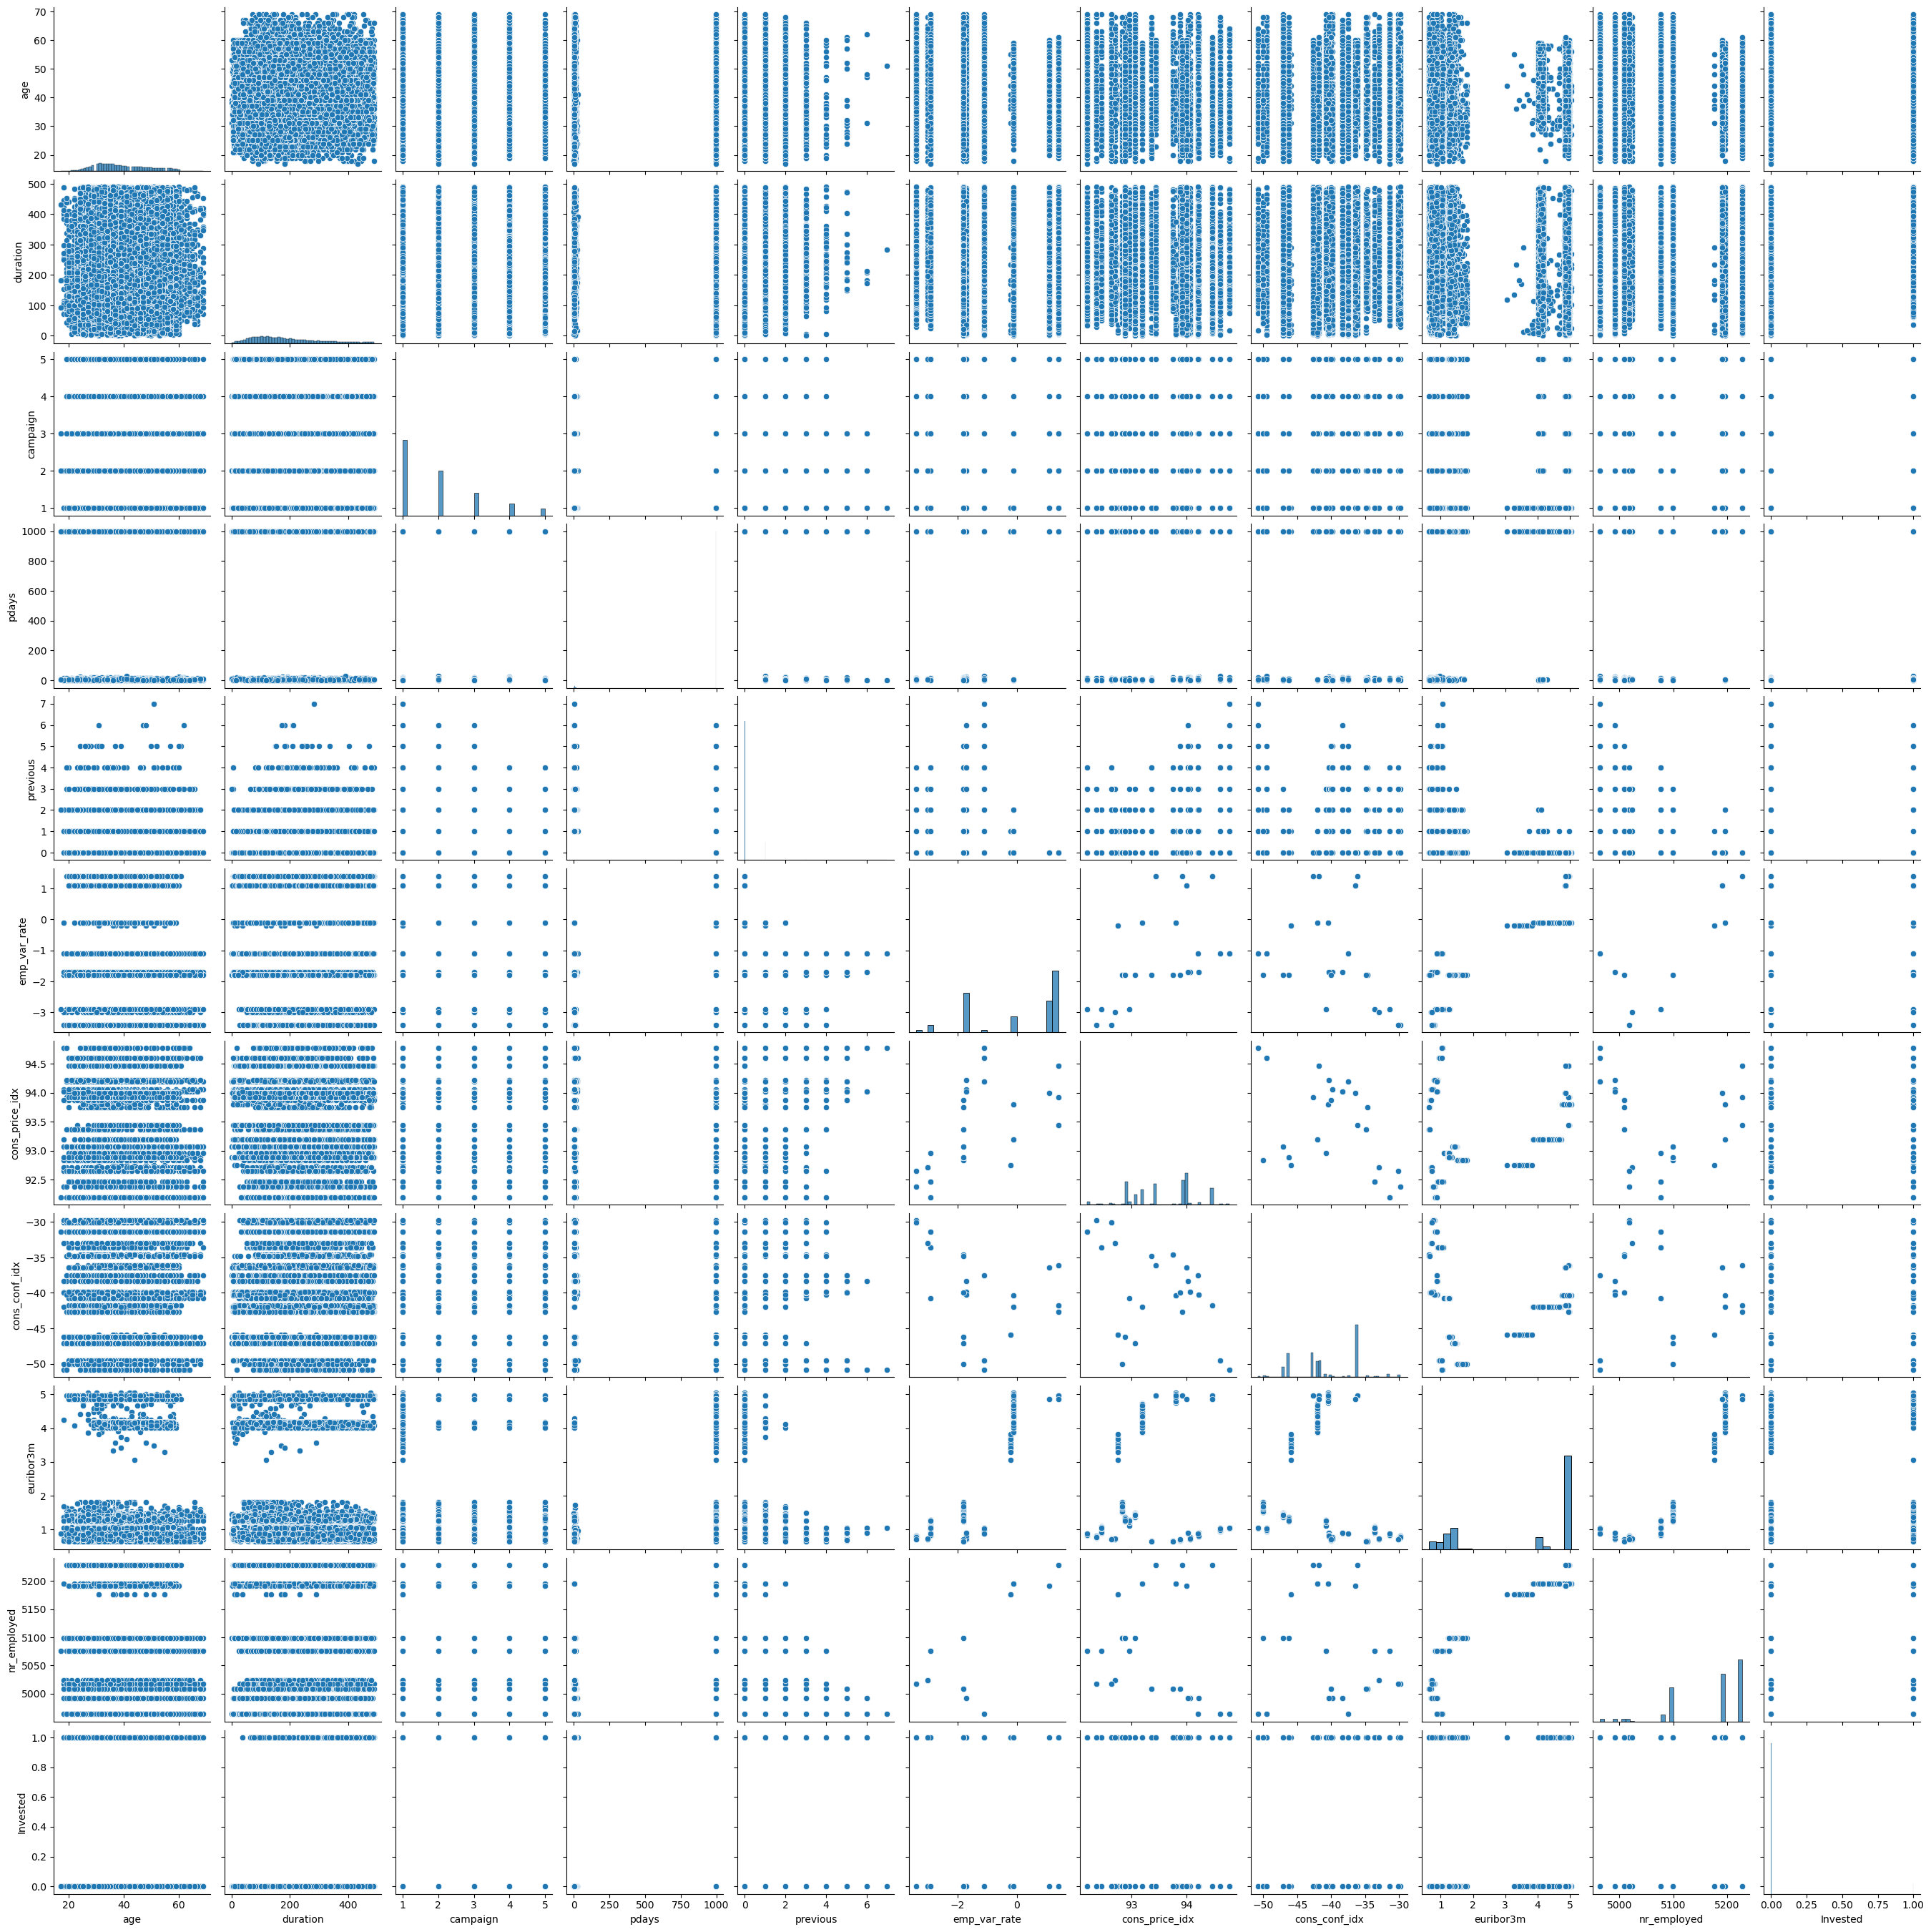

In [45]:
sns.pairplot(df)

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\316555093.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["age"])


<Axes: xlabel='age', ylabel='Density'>

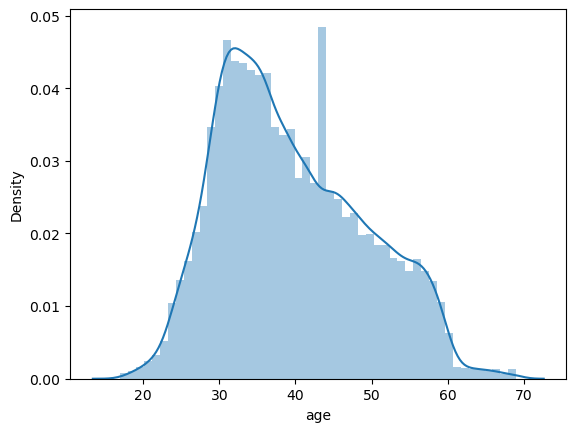

In [46]:
sns.distplot(df["age"])

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\4239709261.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["duration"])


<Axes: xlabel='duration', ylabel='Density'>

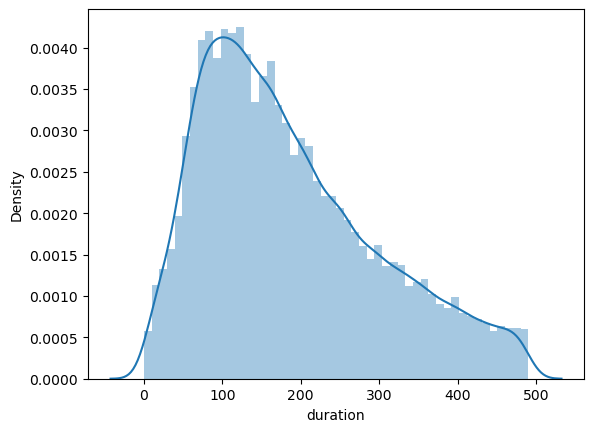

In [47]:
sns.distplot(df["duration"])

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\4094758516.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["campaign"])


<Axes: xlabel='campaign', ylabel='Density'>

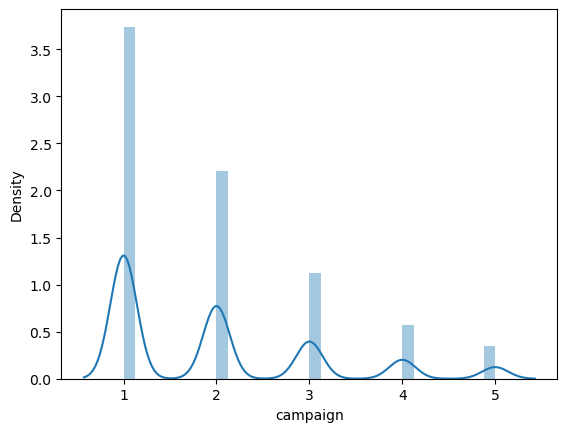

In [48]:
sns.distplot(df["campaign"])

In [49]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\4002213783.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["emp_var_rate"])


<Axes: xlabel='emp_var_rate', ylabel='Density'>

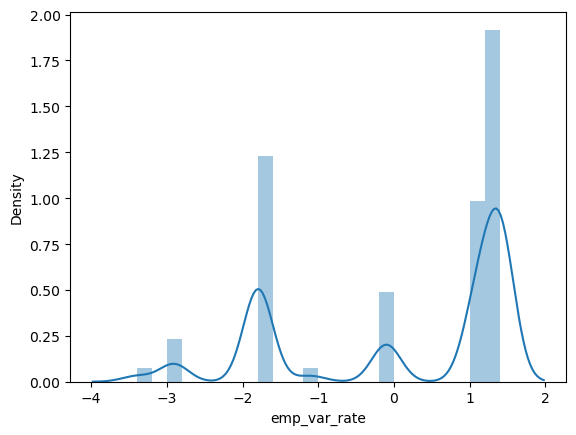

In [50]:
sns.distplot(df["emp_var_rate"])

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\3182414421.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["cons_price_idx"])


<Axes: xlabel='cons_price_idx', ylabel='Density'>

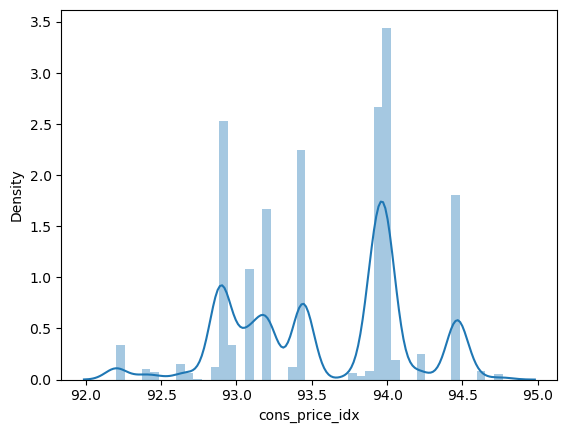

In [51]:
sns.distplot(df["cons_price_idx"])

C:\Users\Srushti Patil\AppData\Local\Temp\ipykernel_2368\3856098881.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["cons_conf_idx"])


<Axes: xlabel='cons_conf_idx', ylabel='Density'>

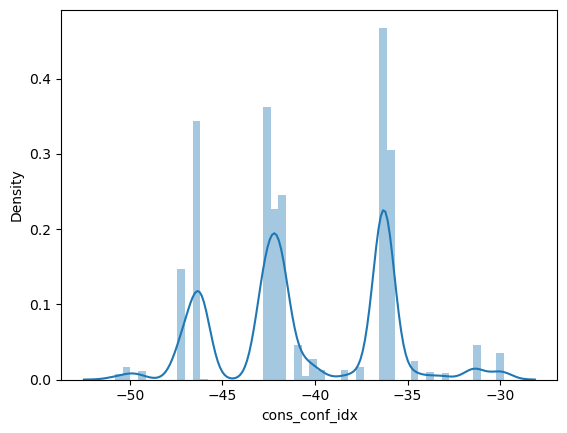

In [52]:
sns.distplot(df["cons_conf_idx"])

#### Data mix using groupby() for non numeric data

<Axes: xlabel='job'>

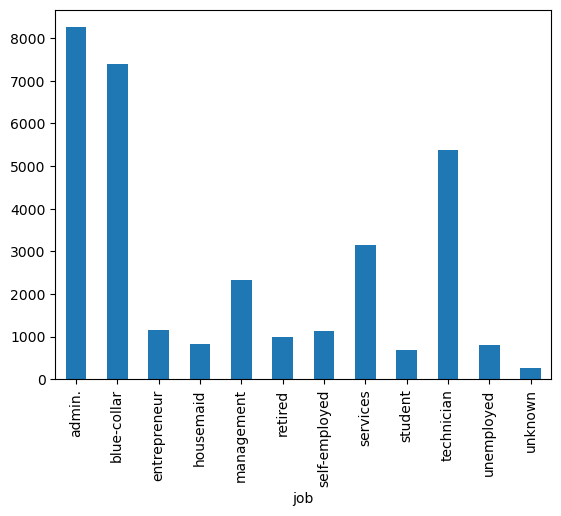

In [53]:
df.groupby("job")["job"].count().plot(kind="bar")

In [54]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

<Axes: xlabel='marital'>

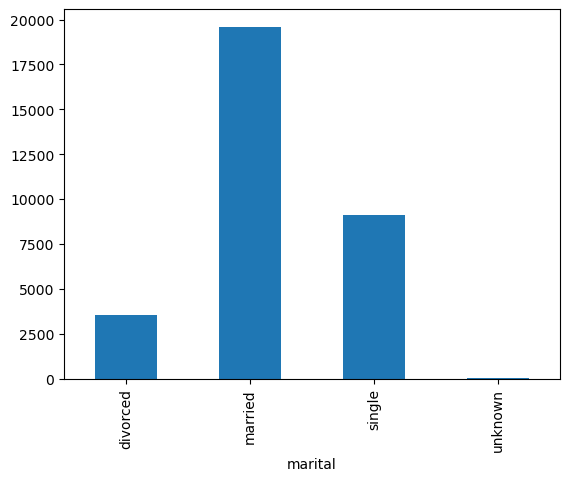

In [55]:
df.groupby("marital")["marital"].count().plot(kind="bar")

<Axes: xlabel='education'>

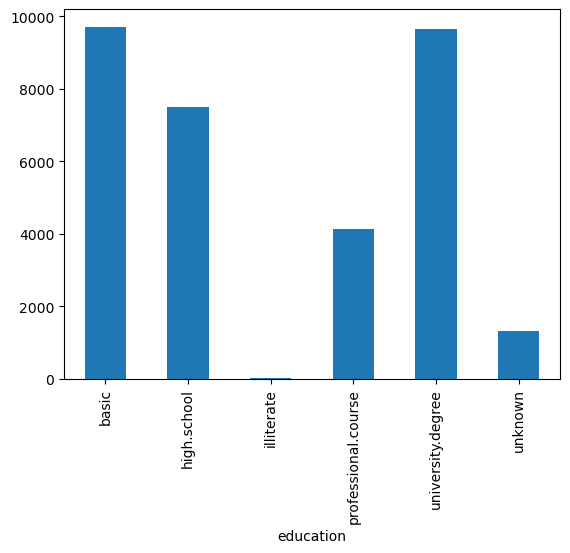

In [56]:
df.groupby("education")["education"].count().plot(kind="bar")

<Axes: xlabel='default'>

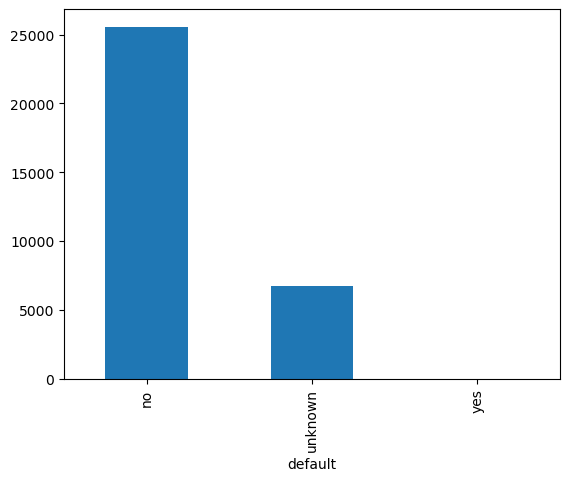

In [57]:
df.groupby("default")["default"].count().plot(kind="bar")

In [58]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx',
       'cons_conf_idx', 'euribor3m', 'nr_employed', 'Invested'],
      dtype='object')

<Axes: xlabel='housing'>

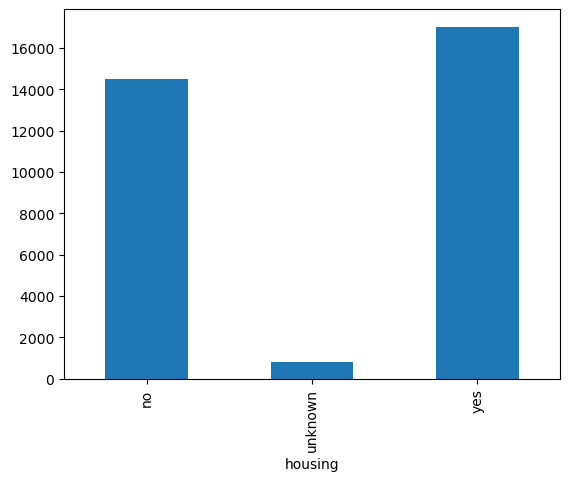

In [59]:
df.groupby("housing")["housing"].count().plot(kind="bar")

<Axes: xlabel='loan'>

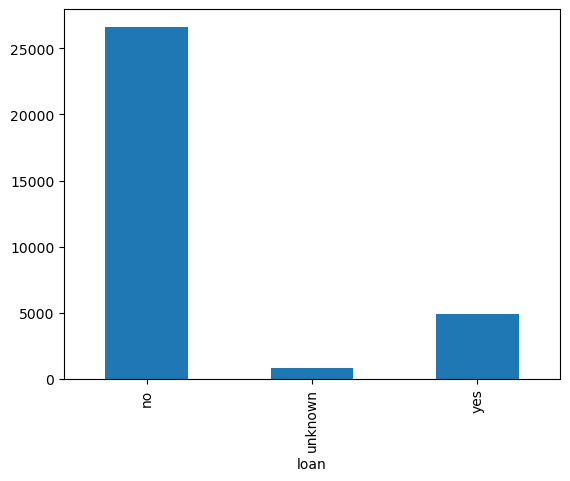

In [60]:
df.groupby("loan")["loan"].count().plot(kind="bar")

<Axes: xlabel='Invested'>

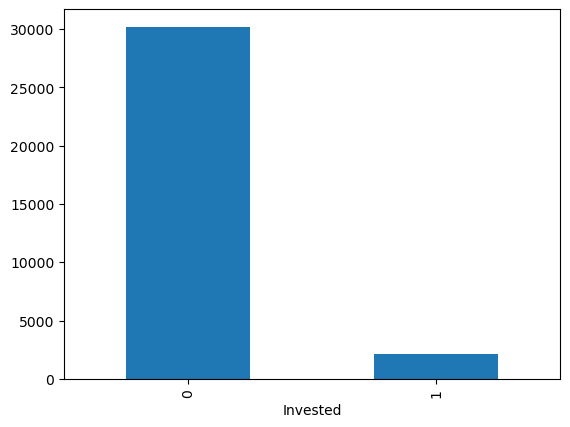

In [61]:
df.groupby("Invested")["Invested"].count().plot(kind="bar")

#### uses correlation 

In [62]:
df_numeric=df.select_dtypes(include=['int32','int64','float32','float64'])
df_numeric.head()

,age,duration,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,Invested
0,44,210,1,999,0,1.4,93.444,-36.1,4.963,5228.1,0
1,53,138,1,999,0,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,339,3,6,2,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,185,2,999,0,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,137,1,3,1,-2.9,92.201,-31.4,0.869,5076.2,1


In [63]:
df_numeric=df_numeric.drop(['campaign','pdays','previous'],axis=1)
df_numeric.head()

,age,duration,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,Invested
0,44,210,1.4,93.444,-36.1,4.963,5228.1,0
1,53,138,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,339,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,185,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,137,-2.9,92.201,-31.4,0.869,5076.2,1


<Axes: >

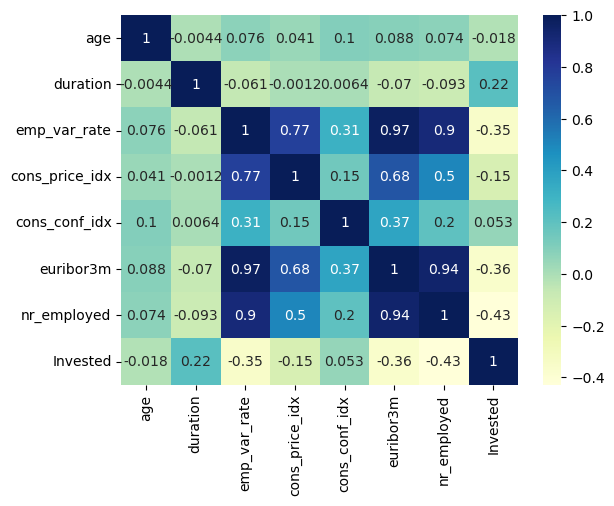

In [64]:
sns.heatmap(df_numeric.corr(),cmap="YlGnBu",annot=True)

In [65]:
col_to_drop=['contact', 'month', 'day_of_week', 'campaign', 
             'pdays','previous', 'poutcome']
df=df.drop(col_to_drop, axis=1) 

In [66]:
df_categorical=df.select_dtypes(include='object')
df_categorical

,job,marital,education,default,housing,loan
0,blue-collar,married,basic,unknown,yes,no
1,technician,married,unknown,no,no,no
2,management,single,university.degree,no,yes,no
3,services,married,high.school,no,no,no
4,retired,married,basic,no,yes,no
...,...,...,...,...,...,...
41182,admin.,married,high.school,no,yes,no
41183,retired,married,high.school,unknown,no,yes
41184,housemaid,married,basic,unknown,no,no
41185,admin.,single,university.degree,unknown,yes,yes


In [67]:
df_dummy=pd.get_dummies(df_categorical,drop_first=True)
df_dummy.head()

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,...,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes
0,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,False,False
1,False,False,False,False,False,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False
3,False,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [68]:
df_final=pd.concat([df_numeric,df_dummy],axis=1)
df_final.head()

,age,duration,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,Invested,job_blue-collar,job_entrepreneur,...,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes
0,44,210,1.4,93.444,-36.1,4.963,5228.1,0,True,False,...,False,False,False,False,True,False,False,True,False,False
1,53,138,-0.1,93.200,-42.0,4.021,5195.8,0,False,False,...,False,False,False,True,False,False,False,False,False,False
2,28,339,-1.7,94.055,-39.8,0.729,4991.6,1,False,False,...,False,False,True,False,False,False,False,True,False,False
3,39,185,-1.8,93.075,-47.1,1.405,5099.1,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,55,137,-2.9,92.201,-31.4,0.869,5076.2,1,False,False,...,False,False,False,False,False,False,False,True,False,False


In [69]:
x=df_final.drop('Invested',axis=1) # remove target variable and keep all data in x
y=df_final['Invested'] # keep only target data in y

In [71]:
print(x.shape,y.shape)

(32334, 32) (32334,)


In [72]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,train_size=0.7,random_state=999)
print(xtrain.shape,xtest.shape,ytrain.shape,ytest.shape)

(22633, 32) (9701, 32) (22633,) (9701,)


In [73]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif

In [74]:
key_features=SelectKBest(score_func=f_classif,k=5)
xtrain_selected=key_features.fit_transform(xtrain,ytrain)
selected_indices=key_features.get_support(indices=True)
selected_features=xtrain.columns[selected_indices]

In [75]:
selected_indices

array([1, 2, 3, 5, 6])

In [76]:
x_train=xtrain[selected_features]

In [77]:
x_train.columns

Index(['duration', 'emp_var_rate', 'cons_price_idx', 'euribor3m',
       'nr_employed'],
      dtype='object')

In [78]:
x_test=xtest[selected_features]
x_test.columns

Index(['duration', 'emp_var_rate', 'cons_price_idx', 'euribor3m',
       'nr_employed'],
      dtype='object')

# Logestic Regression

In [79]:
logreg=LogisticRegression()

In [80]:
logreg.fit(xtrain,ytrain)

C:\Users\Srushti Patil\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [81]:
logreg.score(xtrain,ytrain)

0.9446383599169355

In [82]:
y_pred=logreg.predict(xtest)

In [83]:
logreg.score(xtest,ytest)

0.9471188537264199

In [84]:
logreg.fit(x_train,ytrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [85]:
logreg.score(x_train,ytrain)

0.9422524632174258

In [86]:
lr_predicted=logreg.predict(x_test)

In [87]:
logreg.score(x_test,ytest)

0.9450572105968457

In [88]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

In [89]:
confusion_matrix(ytest,lr_predicted)

array([[8961,  120],
       [ 413,  207]])

In [90]:
(8961+207)/(8961+120+413+207)

0.9450572105968457

In [91]:
lr_accuracy=accuracy_score(ytest,lr_predicted)
lr_precision=precision_score(ytest,lr_predicted)
lr_recall=recall_score(ytest,lr_predicted)
lr_f1=f1_score(ytest,lr_predicted)

In [92]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.43717


# KNN Algorithm

In [93]:
from sklearn.neighbors import KNeighborsClassifier

In [94]:
knn=KNeighborsClassifier(n_neighbors=5,metric="euclidean")

In [95]:
knn.fit(x_train,ytrain)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'euclidean'
,metric_params,None
,n_jobs,None


In [96]:
knn_predicted=knn.predict(x_test)

In [97]:
knn_accuracy=accuracy_score(ytest,knn_predicted)
knn_precision=precision_score(ytest,knn_predicted)
knn_recall=recall_score(ytest,knn_predicted)
knn_f1=f1_score(ytest,knn_predicted)

In [98]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.43717
1,KNN,0.942274,0.564935,0.420968,0.48244


# Naive Bayes Algorithm

In [99]:
from sklearn.naive_bayes import GaussianNB 

In [100]:
gnb = GaussianNB()

In [101]:
gnb.fit(x_train,ytrain)

,priors,None
,var_smoothing,1e-09


In [102]:
gnb_predicted=gnb.predict(x_test)

In [103]:
gnb_accuracy=accuracy_score(ytest,gnb_predicted)
gnb_precision=precision_score(ytest,gnb_predicted)
gnb_recall=recall_score(ytest,gnb_predicted)
gnb_f1=f1_score(ytest,gnb_predicted)

In [104]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1],
      ["GNB",gnb_accuracy,gnb_precision,gnb_recall,gnb_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.437170
1,KNN,0.942274,0.564935,0.420968,0.482440
2,GNB,0.783837,0.215195,0.900000,0.347339


# Decision Tree Classifier

#### pruning = removing unwanted or unnessary trees to overcome overfitting and improve models ability 

In [105]:
from sklearn.tree import DecisionTreeClassifier
dtree=DecisionTreeClassifier(max_depth=5)
dtree.fit(xtrain,ytrain)
d_predicted=dtree.predict(xtest)

In [106]:
d_accuracy=accuracy_score(ytest,d_predicted)
d_precision=precision_score(ytest,d_predicted)
d_recall=recall_score(ytest,d_predicted)
d_f1=f1_score(ytest,d_predicted)

In [107]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1],
      ["GNB",gnb_accuracy,gnb_precision,gnb_recall,gnb_f1],
     ["Dtree",d_accuracy,d_precision,d_recall,d_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.437170
1,KNN,0.942274,0.564935,0.420968,0.482440
2,GNB,0.783837,0.215195,0.900000,0.347339
3,Dtree,0.948974,0.624750,0.504839,0.558430


# Random Forest

In [108]:
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier(n_estimators=100)
rfc.fit(xtrain,ytrain)
rfc_predicted=rfc.predict(xtest)

In [109]:
rfc_accuracy=accuracy_score(ytest,rfc_predicted)
rfc_precision=precision_score(ytest,rfc_predicted)
rfc_recall=recall_score(ytest,rfc_predicted)
rfc_f1=f1_score(ytest,rfc_predicted)

In [110]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1],
      ["GNB",gnb_accuracy,gnb_precision,gnb_recall,gnb_f1],
     ["Dtree",d_accuracy,d_precision,d_recall,d_f1],
     ["RFC",rfc_accuracy,rfc_precision,rfc_recall,rfc_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.437170
1,KNN,0.942274,0.564935,0.420968,0.482440
2,GNB,0.783837,0.215195,0.900000,0.347339
3,Dtree,0.948974,0.624750,0.504839,0.558430
4,RFC,0.947737,0.618947,0.474194,0.536986


# Support Vector Machine SVM

In [111]:
from sklearn.svm import SVC #SVC=Support Vector Classifier
svm = SVC(kernel='linear') #linear--for straight line seperation of data 
                           #RBF(Radial Basis Function)--for non linear means curved data seperation
svm.fit(x_train,ytrain)
svm_predicted=svm.predict(x_test)

In [112]:
svm_accuracy=accuracy_score(ytest,svm_predicted)
svm_precision=precision_score(ytest,svm_predicted)
svm_recall=recall_score(ytest,svm_predicted)
svm_f1=f1_score(ytest,svm_predicted)

In [113]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1],
      ["GNB",gnb_accuracy,gnb_precision,gnb_recall,gnb_f1],
     ["Dtree",d_accuracy,d_precision,d_recall,d_f1],
     ["RFC",rfc_accuracy,rfc_precision,rfc_recall,rfc_f1],
     ["SVM",svm_accuracy,svm_precision,svm_recall,svm_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.437170
1,KNN,0.942274,0.564935,0.420968,0.482440
2,GNB,0.783837,0.215195,0.900000,0.347339
3,Dtree,0.948974,0.624750,0.504839,0.558430
4,RFC,0.947737,0.618947,0.474194,0.536986
5,SVM,0.938872,0.800000,0.058065,0.108271


### XG Boost Classifier 
* XGBoost stands for Extreme Gradient Boosting.
* It is an advanced machine learning algorithm based on decision trees. It builds multiple trees sequentially, where each new tree tries to correct errors made by the previous trees.
 

In [114]:
#pip install xgboost

In [115]:
from xgboost import XGBClassifier

In [117]:
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)
 
xgb.fit(xtrain,ytrain)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [ ]:
# n_estimators=100	Builds up to 100 boosting trees
# learning_rate=0.1	Controls each tree's contribution
# max_depth=3	Limits the depth of each tree
# objective="binary:logistic"	Predicts probabilities for two classes
# eval_metric="logloss"	Measures the quality of probability predictions

In [120]:
# Test the XGB model
xgb_pred = xgb.predict(xtest)

In [125]:
#check scores
xgb_accuracy=accuracy_score(ytest, xgb_pred)
xgb_precision=precision_score(ytest, xgb_pred)
xgb_recall=recall_score(ytest, xgb_pred)
xgb_f1=f1_score(ytest, xgb_pred)

In [128]:
col=["Model Name","Accuracy","Precision","Recall","F1-Score"]
data=[["Log reg",lr_accuracy,lr_precision,lr_recall,lr_f1],
      ["KNN ",knn_accuracy,knn_precision,knn_recall,knn_f1],
      ["GNB",gnb_accuracy,gnb_precision,gnb_recall,gnb_f1],
     ["Dtree",d_accuracy,d_precision,d_recall,d_f1],
     ["RFC",rfc_accuracy,rfc_precision,rfc_recall,rfc_f1],
     ["SVM",svm_accuracy,svm_precision,svm_recall,svm_f1],
     ["XG Boost", xgb_accuracy,xgb_precision, xgb_recall,xgb_f1]]
ml_summary=pd.DataFrame(data,columns=col)
ml_summary

,Model Name,Accuracy,Precision,Recall,F1-Score
0,Log reg,0.945057,0.633028,0.333871,0.437170
1,KNN,0.942274,0.564935,0.420968,0.482440
2,GNB,0.783837,0.215195,0.900000,0.347339
3,Dtree,0.948974,0.624750,0.504839,0.558430
4,RFC,0.947737,0.618947,0.474194,0.536986
5,SVM,0.938872,0.800000,0.058065,0.108271
6,XG Boost,0.949696,0.623134,0.538710,0.577855


### These models can also be used for Regression 
* Decision tree regressor
* Random forest Regressor
* SVR - Support Vector Regressor
* XGBoost Regressor
* KNN Regressor
* Naive Bayes Regressor 
 